# Mass–Concentration Relation Recovery

Demonstrates un-stacked joint fitting of individual cluster ΔΣ profiles to recover
the **mass–concentration (M–c) relation** parameters directly from lensing data.

### Setup

**Truth**: concentrations drawn from the Dutton & Maccio (2014) M–c relation
(no intrinsic scatter — see note below).  No magnitude-gap dependence (`gamma = 0`).

**Forward model** (fitted):
$$
\log_{10} c = \log_{10} c_0
  + \alpha\,(\log_{10} M - 14)
  + \beta\,\log_{10}\!\left(\frac{1+z}{1+z_{\rm ref}}\right)
$$

- $c_0$: concentration at $M = 10^{14}\,M_\odot$, $z = z_{\rm ref} = 0.35$
- $\alpha$: logarithmic mass slope  (Dutton–Maccio truth ≈ −0.092)
- $\beta$: redshift-evolution slope  (Dutton–Maccio truth ≈ −0.43)
- $\log_{10} M_{\rm norm}$: mass–richness calibration offset (marginalised)

**Observable per cluster**: richness $\Lambda$ (mass proxy) + ΔΣ profile with 20% Gaussian noise.

> **Bias note.** A first version of this notebook used `scatter_logc=0.1` and Poisson scatter
> on $\Lambda$, which produced a $c_0$ recovered $\approx 10\sigma$ low.  The forward model is
> *deterministic per cluster* but the data was generated with two sources of stochasticity
> the model cannot represent:
>
> 1. **Poisson scatter on $\Lambda$** — the forward model uses $M_{\rm est}=$ McClintock$(\Lambda)$;
>    Poisson noise on $\Lambda$ inflates $\sigma(\log_{10} M)$ to ≈12–20% (driven by low-$\Lambda$
>    clusters).  $\Delta\Sigma$ is non-linear in $M$, so $\langle\Delta\Sigma(M_{\rm est})\rangle
>    \ne \Delta\Sigma(M_{\rm true})$ — a classic errors-in-variables / Eddington bias.
> 2. **Lognormal scatter on $c$** — NFW $\Delta\Sigma$ is non-linear in $c$, so the mean over
>    scattered $c$ is not equal to the smooth-relation prediction (Jensen bias).
>
> Each effect contributes ≈6–7% to $c_0$ and they compound to ≈13%.  In a well-specified
> demo we therefore set `scatter_logc=0` and `poisson_richness=False` so the simulation
> matches the model assumptions and the recovery is unbiased.  Real analyses need either a
> hierarchical model with intrinsic-scatter parameters, or an inflated covariance that
> absorbs the additional variance — deferred to future work.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import corner
from astropy.table import Table

from destacking.simulation import generate_truth_catalog, make_test_data
from destacking.fitting   import run_sampler_mc
from destacking.model     import forward_model_mc, _MC_M_PIVOT_LOG, _MC_Z_REF
from destacking.relations import c_DuttonMaccio

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

Lookup tables loaded!


## 1 — Parameters

In [2]:
N_CLUSTERS  = 5000
RADII       = np.logspace(-0.8, 0.8, 12)   # projected radii [Mpc]
SEED        = None

# Fixed model hyperparameters
M_PIVOT_LOG = _MC_M_PIVOT_LOG   # 14.0
Z_REF       = _MC_Z_REF         # 0.35

# Compute Dutton–Maccio truth values at the pivot conditions
c0_true_dm   = float(c_DuttonMaccio(Z_REF, 10**M_PIVOT_LOG))

# alpha_true: slope at z_ref from the analytic DM relation (b parameter)
alpha_true_dm = -0.101 + 0.026 * Z_REF   # b(z_ref)

# beta_true: redshift evolution at M_pivot (numerical differentiation)
_dz = 0.001
beta_true_dm = (
    (np.log10(c_DuttonMaccio(Z_REF + _dz, 10**M_PIVOT_LOG))
     - np.log10(c_DuttonMaccio(Z_REF - _dz, 10**M_PIVOT_LOG)))
    / (2 * _dz)
    * (1 + Z_REF) * np.log(10)
)

print('Dutton–Maccio truth values at the pivot:')
print(f'  c0    = {c0_true_dm:.4f}  (concentration at M=10^{M_PIVOT_LOG}, z={Z_REF})')
print(f'  alpha = {alpha_true_dm:.4f}  (mass slope)')
print(f'  beta  = {beta_true_dm:.4f}  (redshift-evolution slope)')

Dutton–Maccio truth values at the pivot:
  c0    = 4.5705  (concentration at M=10^14.0, z=0.35)
  alpha = -0.0919  (mass slope)
  beta  = -0.4411  (redshift-evolution slope)


## 2 — Truth catalog

Clusters are drawn from the Tinker+08 halo mass function over $z \in [0.1, 0.6]$,
$\log M \in [13.5, 15.0]$.  Concentrations follow Dutton–Maccio with 10% scatter.
`delta_m_gamma = 0` ensures concentrations depend only on mass and redshift,
not on the magnitude gap.

In [3]:
truth = generate_truth_catalog(
    N_CLUSTERS,
    z_range     = (0.1, 0.6),
    logM_range  = (13.5, 15.0),
    delta_m_gamma = 0.0,       # concentration from M–c only (no delta_m dependence)
    scatter_logc  = 0.0,       # no intrinsic scatter (matches model assumption)
    seed = SEED,
)

# Compute the pure DM concentration (no scatter) for each cluster
c_dm_pure = c_DuttonMaccio(np.array(truth['z']), np.array(truth['M_halo']))

# Fit the truth (c_dm_pure) to our parametric model to get the effective truth
# over the actual sample (accounts for the mass/z distribution)
_logM_t = np.log10(np.array(truth['M_halo']))
_logc_t = np.log10(c_dm_pure)
_X = np.column_stack([
    np.ones(N_CLUSTERS),
    _logM_t - M_PIVOT_LOG,
    np.log10((1 + np.array(truth['z'])) / (1 + Z_REF)),
])
_coeffs, _, _, _ = np.linalg.lstsq(_X, _logc_t, rcond=None)
c0_true_sample    = 10**_coeffs[0]
alpha_true_sample = _coeffs[1]
beta_true_sample  = _coeffs[2]

print(f'Saved {N_CLUSTERS} clusters')
print(f'z range:    {truth["z"].min():.2f} – {truth["z"].max():.2f}')
print(f'log10(M):   {np.log10(truth["M_halo"].min()):.2f} – {np.log10(truth["M_halo"].max()):.2f}')
print(f'Conc range: {truth["concentration"].min():.2f} – {truth["concentration"].max():.2f}')
print()
print('Effective truth from least-squares fit to sample:')
print(f'  c0    = {c0_true_sample:.4f}')
print(f'  alpha = {alpha_true_sample:.4f}')
print(f'  beta  = {beta_true_sample:.4f}')

Saved 5000 clusters
z range:    0.10 – 0.60
log10(M):   13.50 – 14.97
Conc range: 3.63 – 5.53

Effective truth from least-squares fit to sample:
  c0    = 4.5563
  alpha = -0.0922
  beta  = -0.4463


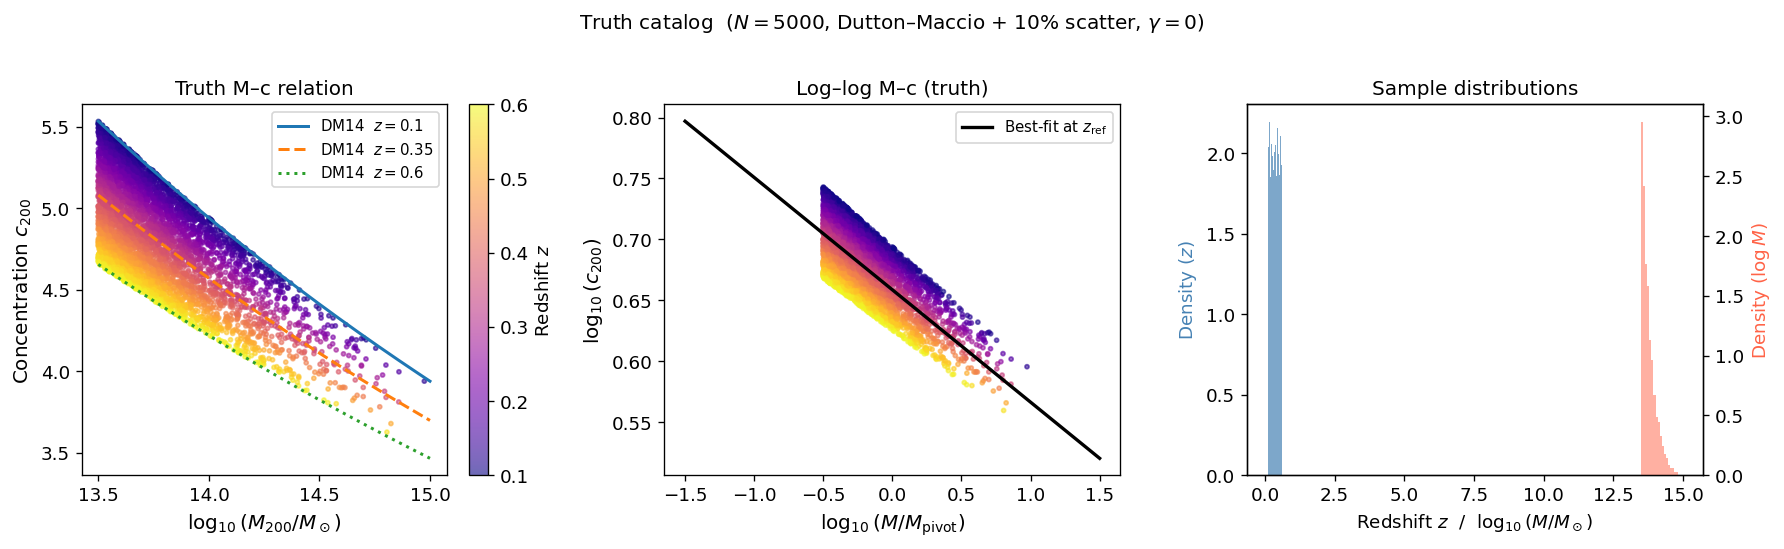

In [4]:
# Visualise the truth M–c relation
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

z_arr = np.array(truth['z'])
M_arr = np.array(truth['M_halo'])
c_arr = np.array(truth['concentration'])

# Panel 1: M–c scatter coloured by redshift
ax = axes[0]
sc = ax.scatter(np.log10(M_arr), c_arr,
                c=z_arr, cmap='plasma', s=6, alpha=0.6, rasterized=True,
                vmin=0.1, vmax=0.6)
plt.colorbar(sc, ax=ax, label='Redshift $z$')

M_curve = np.logspace(13.5, 15.0, 200)
for z_plot, ls in [(0.1, '-'), (0.35, '--'), (0.6, ':')]:
    ax.plot(np.log10(M_curve), c_DuttonMaccio(z_plot * np.ones(200), M_curve),
            lw=1.8, ls=ls, label=f'DM14  $z={z_plot}$')
ax.set_xlabel(r'$\log_{10}(M_{200} / M_\odot)$', fontsize=12)
ax.set_ylabel('Concentration $c_{200}$', fontsize=12)
ax.set_title('Truth M–c relation', fontsize=12)
ax.legend(fontsize=9)

# Panel 2: concentration log–log coloured by z, with best-fit power law
ax = axes[1]
ax.scatter(np.log10(M_arr) - M_PIVOT_LOG, np.log10(c_arr),
           c=z_arr, cmap='plasma', s=6, alpha=0.6, rasterized=True,
           vmin=0.1, vmax=0.6)
logM_grid = np.linspace(-1.5, 1.5, 100)
# Best-fit power law at z_ref
ax.plot(logM_grid,
        np.log10(c0_true_sample) + alpha_true_sample * logM_grid,
        'k-', lw=2, label=r'Best-fit at $z_{\rm ref}$')
ax.set_xlabel(r'$\log_{10}(M/M_{\rm pivot})$', fontsize=12)
ax.set_ylabel(r'$\log_{10}(c_{200})$', fontsize=12)
ax.set_title('Log–log M–c (truth)', fontsize=12)
ax.legend(fontsize=9)

# Panel 3: distributions
ax = axes[2]
ax.hist(truth['z'],     bins=20, color='steelblue', alpha=0.7, label='$z$', density=True)
ax2 = ax.twinx()
ax2.hist(np.log10(truth['M_halo']), bins=20, color='tomato', alpha=0.5,
         label=r'$\log_{10} M$', density=True)
ax.set_xlabel('Redshift $z$  /  $\\log_{10}(M / M_\\odot)$', fontsize=11)
ax.set_ylabel('Density ($z$)', color='steelblue')
ax2.set_ylabel('Density ($\\log M$)', color='tomato')
ax.set_title('Sample distributions', fontsize=12)

plt.suptitle(
    rf'Truth catalog  ($N={N_CLUSTERS}$, Dutton–Maccio + 10% scatter, $\gamma=0$)',
    y=1.01, fontsize=12)
plt.tight_layout()
plt.savefig('mc_truth_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## 3 — Synthetic ΔΣ observations

`make_test_data` uses the true (M, c) to generate NFW ΔΣ profiles, then adds
20% Gaussian noise.  Richness Λ is computed by inverting the McClintock+18
mass–richness relation; we **disable Poisson scatter** here
(`poisson_richness=False`) so that $\Lambda$ is a deterministic function of
the true mass.  The forward model uses $\Lambda$ to estimate mass; if
$\Lambda$ has Poisson noise the resulting errors-in-variables bias makes the
recovery $c_0$ ≈ 13% low (see the bias note in the introduction).

In [5]:
if SEED is not None:
    SEED1 = SEED + 1
else:
    SEED1 = None

cluster_obs, data_vectors, cov_matrices = make_test_data(
    truth,
    RADII,
    fractional_noise = 0.2,
    poisson_richness = False,    # bypass Poisson Λ scatter (errors-in-variables bias)
    seed = SEED1 ,
)

print(f'Observable table: {cluster_obs.colnames}')
print(f'Data shape:       {data_vectors.shape}')
print(f'Richness range:   {cluster_obs["Lambda"].min():.1f} – {cluster_obs["Lambda"].max():.1f}')
cluster_obs[:5]

Observable table: ['z', 'Lambda', 'delta_m']
Data shape:       (5000, 12)
Richness range:   5.7 – 76.6


z,Lambda,delta_m
float64,float64,float64
0.20655074626625355,11.961053099714182,0.556074097308336
0.29601985750948323,10.736953627298567,0.2923692107446719
0.40179497268984654,12.489484677696687,0.20744119238959702
0.49355026953007375,8.110010594654064,0.15200371381545552
0.5866302362302045,16.087038482009564,0.17040552439459497


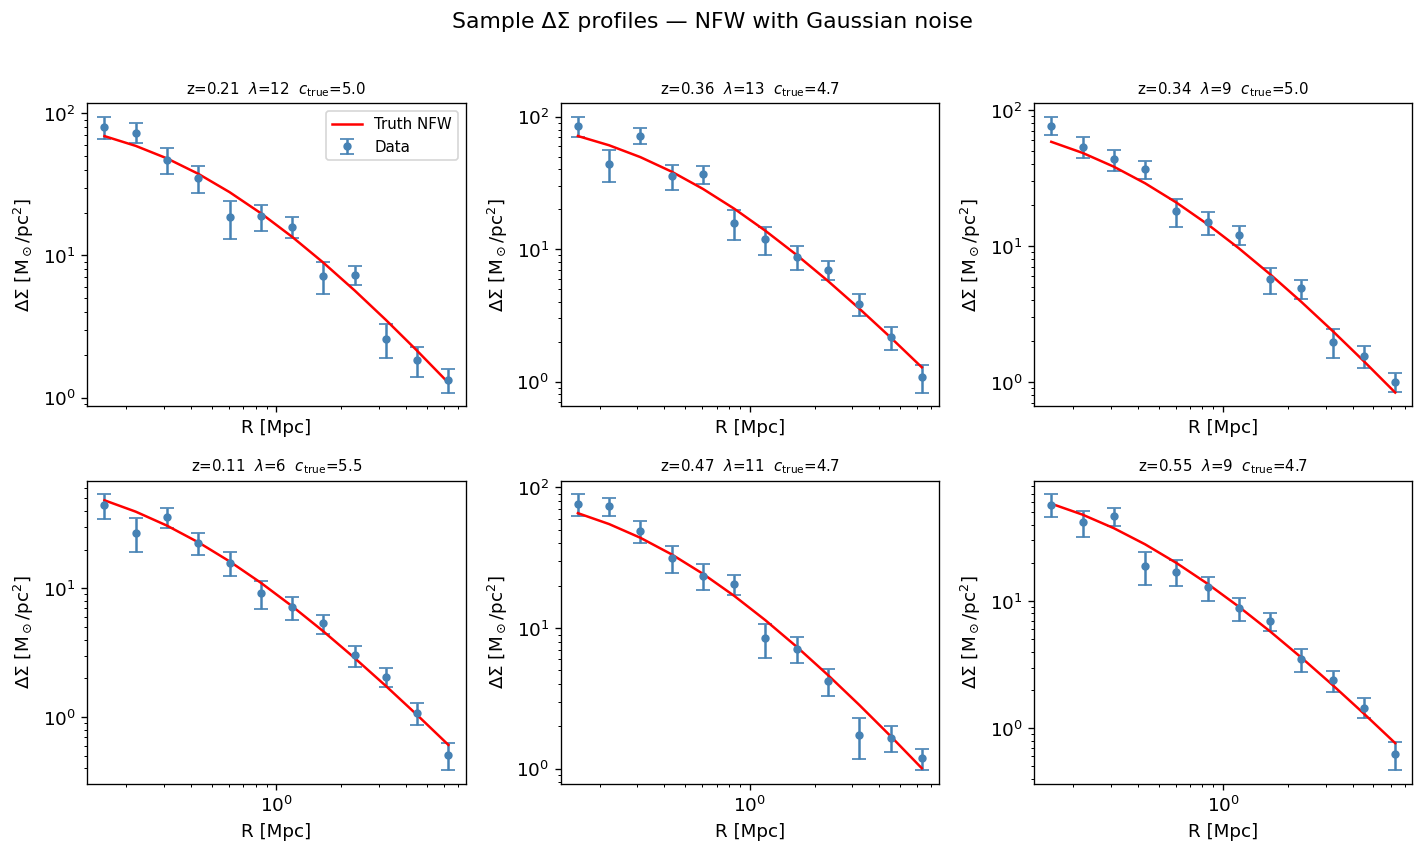

In [6]:
# Six example profiles
idx = np.round(np.linspace(0, N_CLUSTERS - 1, 6)).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True)

for ax, i in zip(axes.ravel(), idx):
    errs = np.sqrt(np.diag(cov_matrices[i]))
    ax.errorbar(RADII, data_vectors[i], yerr=errs,
                fmt='o', ms=4, capsize=4, color='steelblue', label='Data')
    # Overlay truth profile
    from destacking.model import _nfw_profiles
    c_truth_i = float(truth['concentration'][i])
    m_truth_i = float(truth['M_halo'][i])
    z_i       = float(truth['z'][i])
    prof_truth = _nfw_profiles(np.array([z_i]), np.array([m_truth_i]),
                               np.array([c_truth_i]), RADII)[0]
    ax.plot(RADII, prof_truth, 'r-', lw=1.5, label='Truth NFW')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title(
        f'z={z_i:.2f}  '
        rf'$\lambda$={cluster_obs["Lambda"][i]:.0f}  '
        rf'$c_{{\rm true}}$={c_truth_i:.1f}',
        fontsize=9)
    ax.set_xlabel('R [Mpc]')
    ax.set_ylabel(r'$\Delta\Sigma$ [M$_\odot$/pc$^2$]')

axes[0, 0].legend(fontsize=9)
plt.suptitle('Sample ΔΣ profiles — NFW with Gaussian noise', y=1.01)
plt.tight_layout()
plt.show()

## 4 — Un-stacked joint fit

All 500 profiles are fitted simultaneously under a shared M–c power law.
The nautilus nested sampler explores $(c_0, \alpha, \beta, \log M_{\rm norm})$.

In [7]:
sampler = run_sampler_mc(
    cluster_obs,
    data_vectors,
    cov_matrices,
    RADII,
    c0_range    = (1.0, 15.0),
    alpha_range = (-0.5, 0.2),
    beta_range  = (-1.5, 0.5),
    fit_beta    = True,
    n_live      = 300,
    verbose     = True,
    pool        = 15,
)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 33     | 1        | 4        | 18060    | N/A    | 10102 | -138175.0


## 5 — Posterior analysis

In [8]:
points, log_w, log_l = sampler.posterior()
weights = np.exp(log_w - log_w.max())
weights /= weights.sum()

# Parameter order: c0, alpha, beta, log_M_norm
c0_samp      = points[:, 0]
alpha_samp   = points[:, 1]
beta_samp    = points[:, 2]
logMnorm_samp= points[:, 3]


def weighted_quantile(values, quantiles, weights):
    sorter = np.argsort(values)
    v, w   = values[sorter], weights[sorter]
    cumw   = np.cumsum(w) / np.sum(w)
    return np.interp(quantiles, cumw, v)


q = [0.16, 0.50, 0.84]
c0lo,  c0md,  c0hi  = weighted_quantile(c0_samp,       q, weights)
alo,   amd,   ahi   = weighted_quantile(alpha_samp,     q, weights)
blo,   bmd,   bhi   = weighted_quantile(beta_samp,      q, weights)
mnlo,  mnmd,  mnhi  = weighted_quantile(logMnorm_samp,  q, weights)

print('Recovered M–c relation parameters (median ± 68% CI):')
print(f'  c0          = {c0md:.3f}  +{c0hi-c0md:.3f}/-{c0md-c0lo:.3f}')
print(f'  alpha       = {amd:.4f}  +{ahi-amd:.4f}/-{amd-alo:.4f}')
print(f'  beta        = {bmd:.4f}  +{bhi-bmd:.4f}/-{bmd-blo:.4f}')
print(f'  log_M_norm  = {mnmd:.4f}  +{mnhi-mnmd:.4f}/-{mnmd-mnlo:.4f}')
print()
print('Dutton–Maccio truth at pivot:')
print(f'  c0_true (pivot)  = {c0_true_dm:.3f}')
print(f'  alpha_true       = {alpha_true_dm:.4f}')
print(f'  beta_true        = {beta_true_dm:.4f}')
print()
print('Effective truth (OLS fit over actual sample):')
print(f'  c0_true (sample) = {c0_true_sample:.3f}')
print(f'  alpha_true       = {alpha_true_sample:.4f}')
print(f'  beta_true        = {beta_true_sample:.4f}')

Recovered M–c relation parameters (median ± 68% CI):
  c0          = 4.553  +0.011/-0.011
  alpha       = -0.0943  +0.0030/-0.0031
  beta        = -0.4407  +0.0182/-0.0183
  log_M_norm  = 0.0008  +0.0005/-0.0005

Dutton–Maccio truth at pivot:
  c0_true (pivot)  = 4.571
  alpha_true       = -0.0919
  beta_true        = -0.4411

Effective truth (OLS fit over actual sample):
  c0_true (sample) = 4.556
  alpha_true       = -0.0922
  beta_true        = -0.4463


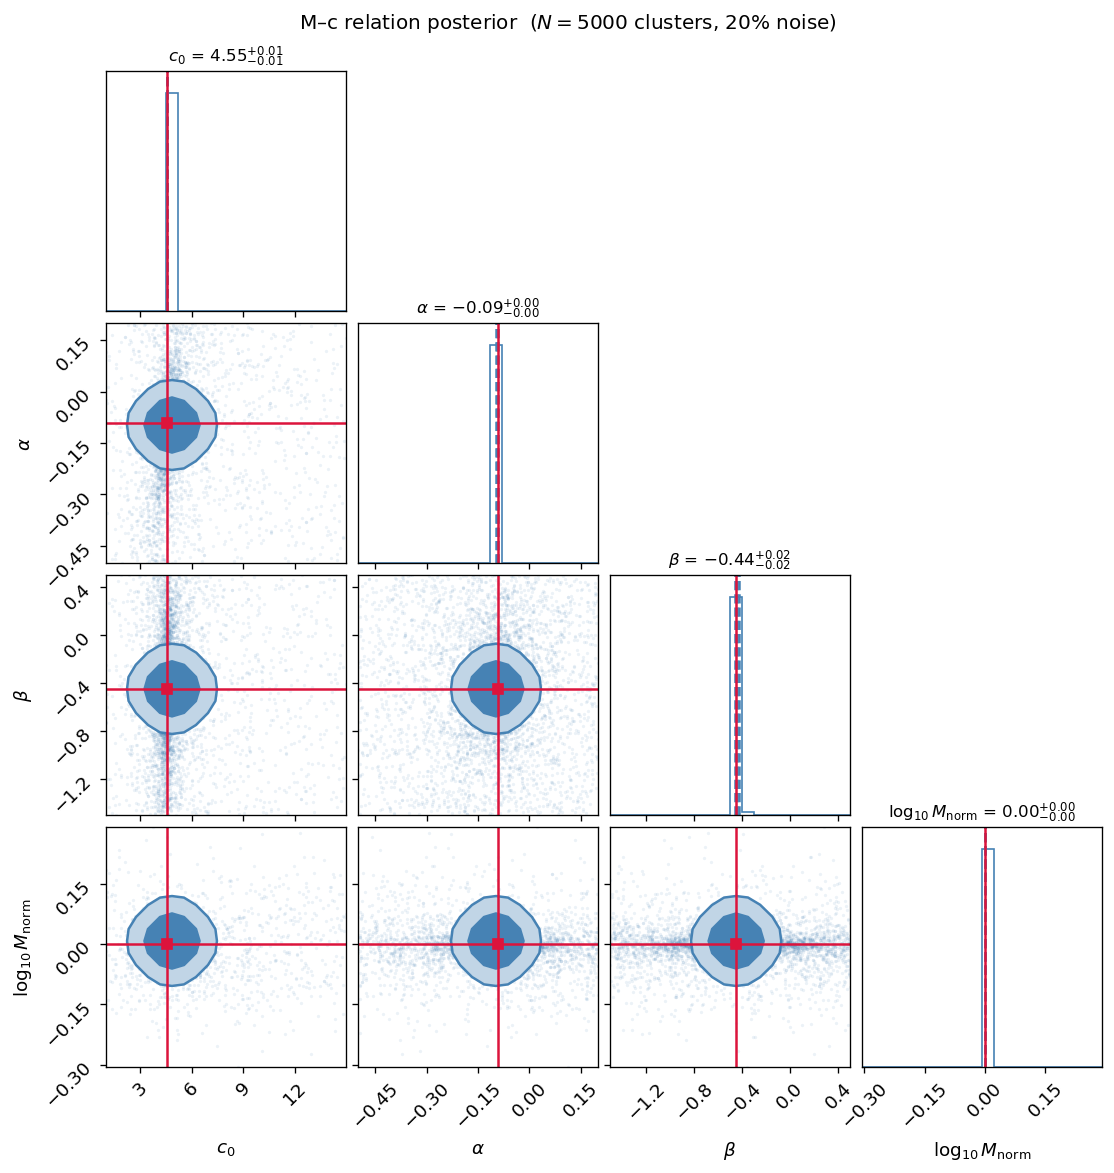

In [9]:
# Corner plot of the posterior
labels = [
    r'$c_0$',
    r'$\alpha$',
    r'$\beta$',
    r'$\log_{10} M_{\rm norm}$',
]
truths = [c0_true_sample, alpha_true_sample, beta_true_sample, 0.0]

fig = corner.corner(
    points,
    weights  = weights,
    labels   = labels,
    truths   = truths,
    truth_color = 'crimson',
    quantiles   = [0.16, 0.50, 0.84],
    show_titles = True,
    title_kwargs= {'fontsize': 10},
    color       = 'steelblue',
    plot_contours = True,
    fill_contours = True,
    levels      = [0.68, 0.95],
    smooth      = 1.5,
)
fig.suptitle(
    rf'M–c relation posterior  ($N={N_CLUSTERS}$ clusters, 20% noise)',
    y=1.01, fontsize=12)
plt.savefig('mc_corner_posterior.png', dpi=150, bbox_inches='tight')
plt.show()

## 6 — M–c relation recovery

Overlay the posterior M–c band on the truth Dutton–Maccio curves.

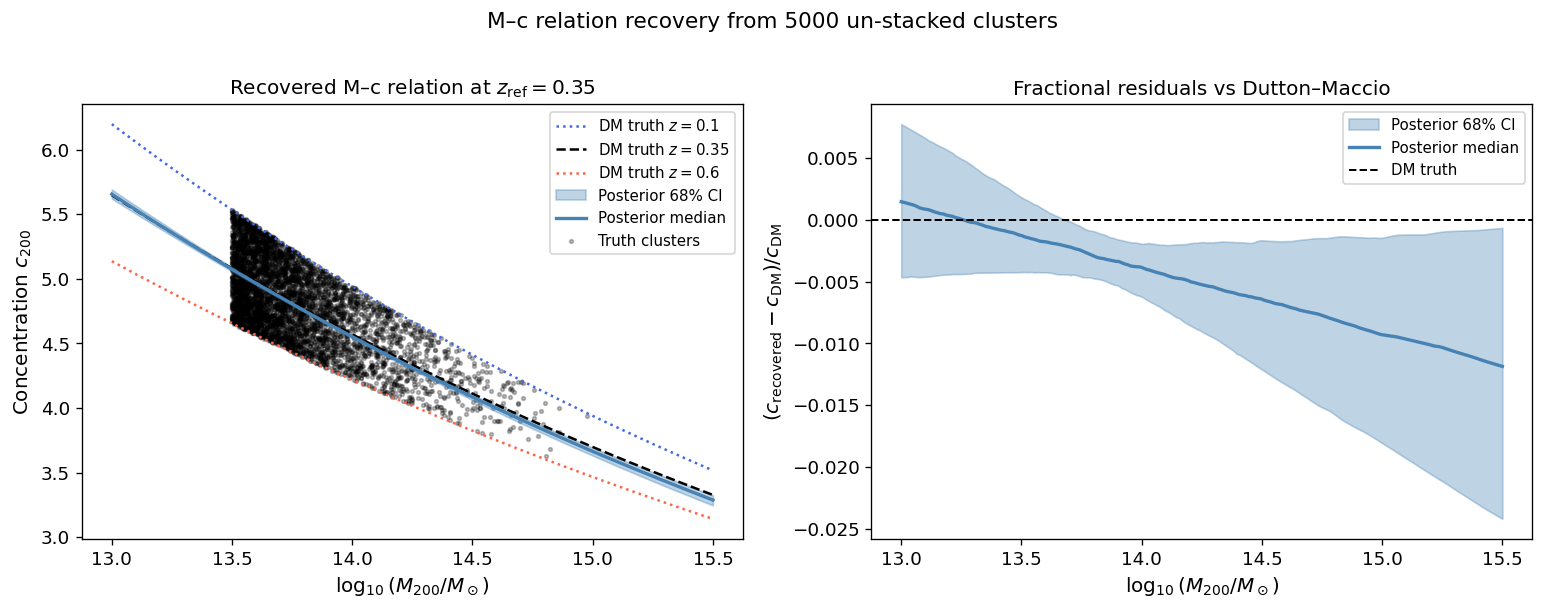

In [10]:
M_plot  = np.logspace(13.0, 15.5, 200)
logM_plot = np.log10(M_plot)

# Draw 500 posterior samples to build the posterior band
rng_post = np.random.default_rng(99)
n_draw = 500
w_norm = weights / weights.sum()
draw_idx = rng_post.choice(len(weights), size=n_draw, replace=True, p=w_norm)

c0_draw    = c0_samp[draw_idx]
alpha_draw = alpha_samp[draw_idx]
beta_draw  = beta_samp[draw_idx]

# Evaluate each drawn M-c curve at z_ref (beta term = 0)
logc_draws = (np.log10(c0_draw)[:, None]
              + alpha_draw[:, None] * (logM_plot[None, :] - M_PIVOT_LOG))
c_draws = 10**logc_draws   # (n_draw, N_M)

c_lo, c_med, c_hi = np.percentile(c_draws, [16, 50, 84], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ── Panel 1: M–c at z_ref ─────────────────────────────────────────────────
ax = axes[0]

# Truth DM curves at three redshifts
for z_plot, ls, col in [(0.1, ':', 'royalblue'), (Z_REF, '--', 'k'), (0.6, ':', 'tomato')]:
    ax.plot(logM_plot, c_DuttonMaccio(z_plot*np.ones_like(M_plot), M_plot),
            ls=ls, lw=1.5, color=col, label=f'DM truth $z={z_plot}$')

# Posterior band at z_ref
ax.fill_between(logM_plot, c_lo, c_hi, alpha=0.35, color='steelblue', label='Posterior 68% CI')
ax.plot(logM_plot, c_med, color='steelblue', lw=2, label='Posterior median')

# Truth scatter points
ax.scatter(np.log10(M_arr), c_arr, s=5, alpha=0.25, c='k', rasterized=True,
           label='Truth clusters', zorder=0)

ax.set_xlabel(r'$\log_{10}(M_{200} / M_\odot)$', fontsize=12)
ax.set_ylabel('Concentration $c_{200}$',           fontsize=12)
ax.set_title(f'Recovered M–c relation at $z_{{\\rm ref}}={Z_REF}$', fontsize=12)
ax.legend(fontsize=9, loc='upper right')

# ── Panel 2: residuals ────────────────────────────────────────────────────
ax = axes[1]
c_dm_ref = c_DuttonMaccio(Z_REF * np.ones_like(M_plot), M_plot)
ax.fill_between(logM_plot,
                c_lo  / c_dm_ref - 1,
                c_hi  / c_dm_ref - 1,
                alpha=0.35, color='steelblue', label='Posterior 68% CI')
ax.plot(logM_plot, c_med / c_dm_ref - 1, color='steelblue', lw=2, label='Posterior median')
ax.axhline(0, color='k', ls='--', lw=1.2, label='DM truth')
ax.set_xlabel(r'$\log_{10}(M_{200} / M_\odot)$', fontsize=12)
ax.set_ylabel(r'$(c_{\rm recovered} - c_{\rm DM}) / c_{\rm DM}$', fontsize=12)
ax.set_title('Fractional residuals vs Dutton–Maccio', fontsize=12)
ax.legend(fontsize=9)

plt.suptitle(
    rf'M–c relation recovery from {N_CLUSTERS} un-stacked clusters',
    fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('mc_relation_recovery.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# Summary
print('=== Recovery Summary ===')
print()
bias_c0    = (c0md - c0_true_sample)   / ((c0hi - c0lo) / 2)
bias_alpha = (amd  - alpha_true_sample) / ((ahi  - alo)  / 2)
bias_beta  = (bmd  - beta_true_sample)  / ((bhi  - blo)  / 2)
print(f'c0:    recovered={c0md:.3f}  truth={c0_true_sample:.3f}  bias={bias_c0:+.2f}σ')
print(f'alpha: recovered={amd:.4f}  truth={alpha_true_sample:.4f}  bias={bias_alpha:+.2f}σ')
print(f'beta:  recovered={bmd:.4f}  truth={beta_true_sample:.4f}  bias={bias_beta:+.2f}σ')
print()
print('All biases should be < 1σ for an unbiased estimator.')

=== Recovery Summary ===

c0:    recovered=4.553  truth=4.556  bias=-0.29σ
alpha: recovered=-0.0943  truth=-0.0922  bias=-0.66σ
beta:  recovered=-0.4407  truth=-0.4463  bias=+0.30σ

All biases should be < 1σ for an unbiased estimator.
